In [ ]:
%pip install -q qiskit matplotlib pylatexenc

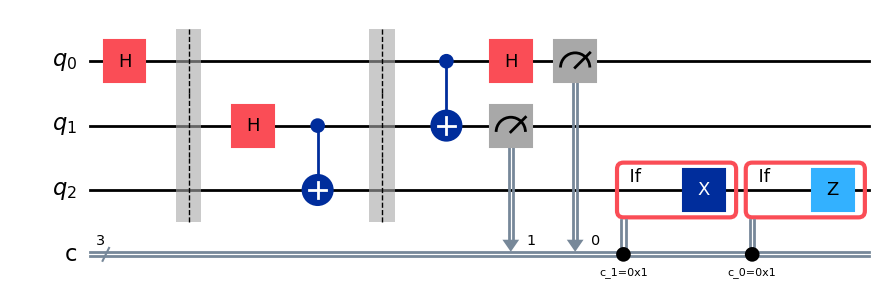

In [ ]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(3, 3)

qc.h(0)

qc.barrier()

qc.h(1)
qc.cx(1, 2)

qc.barrier()

qc.cx(0, 1)
qc.h(0)

qc.measure(0, 0)
qc.measure(1, 1)

with qc.if_test((qc.clbits[1], 1)):
    qc.x(2)

with qc.if_test((qc.clbits[0], 1)):
    qc.z(2)

qc.draw("mpl", fold=-1)

In [ ]:
%pip install -q qiskit-aer

In [ ]:
from qiskit import transpile
from qiskit_aer import AerSimulator

qc_prueba = qc.copy()

qc_prueba.barrier()

qc_prueba.h(2)

qc_prueba.measure(2, 2)

simulador = AerSimulator()

compilado = transpile(
    qc_prueba,
    simulador,
    seed_transpiler=2026
)

shots = 1024

resultado = simulador.run(
    compilado,
    shots=shots,
    seed_simulator=2026
).result()

conteos = resultado.get_counts()

ceros_bob = sum(
    cantidad
    for bits, cantidad in conteos.items()
    if bits[0] == "0"
)

print("Conteos en orden c2 c1 c0:")
print(conteos)

print("\nEjecuciones:", shots)
print("Veces que Bob obtuvo 0 tras la H:", ceros_bob)
print(f"Porcentaje de verificación: {100 * ceros_bob / shots:.2f}%")

Conteos en orden c2 c1 c0:
{'011': 261, '001': 246, '000': 272, '010': 245}

Ejecuciones: 1024
Veces que Bob obtuvo 0 tras la H: 1024
Porcentaje de verificación: 100.00%


In [ ]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator


def preparar_estado(estado):

    preparacion = QuantumCircuit(1)

    if estado == "1":
        preparacion.x(0)

    elif estado == "+":
        preparacion.h(0)

    elif estado == "-":
        preparacion.h(0)
        preparacion.z(0)

    elif estado == "+i":
        preparacion.h(0)
        preparacion.s(0)

    elif estado == "-i":
        preparacion.h(0)
        preparacion.sdg(0)

    elif estado != "0":
        raise ValueError("Estado no reconocido.")

    return preparacion


def crear_circuito(estado):

    preparacion = preparar_estado(estado)
    circuito = QuantumCircuit(3, 3)

    circuito.compose(
        preparacion,
        qubits=[0],
        inplace=True
    )

    circuito.barrier()

    circuito.h(1)
    circuito.cx(1, 2)

    circuito.barrier()

    circuito.cx(0, 1)
    circuito.h(0)

    circuito.measure(0, 0)
    circuito.measure(1, 1)

    with circuito.if_test((circuito.clbits[1], 1)):
        circuito.x(2)

    with circuito.if_test((circuito.clbits[0], 1)):
        circuito.z(2)

    circuito.barrier()

    circuito.compose(
        preparacion.inverse(),
        qubits=[2],
        inplace=True
    )

    circuito.measure(2, 2)

    return circuito


estados = ["0", "1", "+", "-", "+i", "-i"]
shots = 1024

simulador = AerSimulator()
resultados_teleportacion = []

print("Estado | Verificaciones correctas | Fidelidad estimada")

for i, estado in enumerate(estados):

    circuito = crear_circuito(estado)

    compilado = transpile(
        circuito,
        simulador,
        seed_transpiler=2026
    )

    resultado = simulador.run(
        compilado,
        shots=shots,
        seed_simulator=2026 + i
    ).result()

    conteos = resultado.get_counts()

    exitos = sum(
        cantidad
        for bits, cantidad in conteos.items()
        if bits[0] == "0"
    )

    fidelidad = exitos / shots

    resultados_teleportacion.append({
        "estado": estado,
        "shots": shots,
        "exitos": exitos,
        "fidelidad": fidelidad,
        "conteos": conteos
    })

    print(
        f"{estado:>6} | "
        f"{exitos:>10}/{shots:<10} | "
        f"{fidelidad:.4f}"
    )

fidelidad_promedio = sum(
    fila["fidelidad"]
    for fila in resultados_teleportacion
) / len(resultados_teleportacion)

print(f"\nFidelidad promedio: {fidelidad_promedio:.4f}")

Estado | Verificaciones correctas | Fidelidad estimada
     0 |       1024/1024       | 1.0000
     1 |       1024/1024       | 1.0000
     + |       1024/1024       | 1.0000
     - |       1024/1024       | 1.0000
    +i |       1024/1024       | 1.0000
    -i |       1024/1024       | 1.0000

Fidelidad promedio: 1.0000


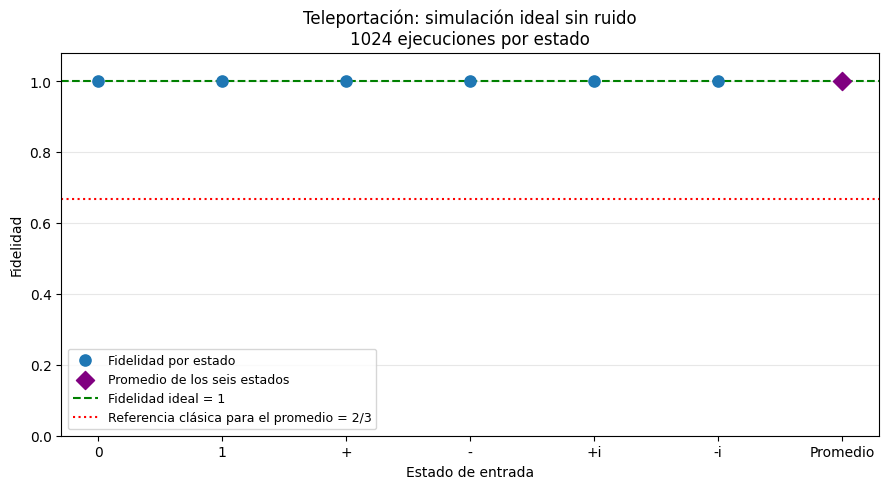

Archivos guardados:
teleportacion_fidelidades_simuladas.csv
teleportacion_conteos_simulados.json
teleportacion_fidelidades_simuladas.png


In [ ]:
import csv
import json
import matplotlib.pyplot as plt

archivo_csv = "teleportacion_fidelidades_simuladas.csv"

with open(
    archivo_csv,
    mode="w",
    newline="",
    encoding="utf-8"
) as archivo:

    escritor = csv.writer(archivo)

    escritor.writerow([
        "estado",
        "ejecuciones",
        "verificaciones_correctas",
        "fidelidad_estimada"
    ])

    for fila in resultados_teleportacion:
        escritor.writerow([
            fila["estado"],
            fila["shots"],
            fila["exitos"],
            fila["fidelidad"]
        ])


archivo_json = "teleportacion_conteos_simulados.json"

datos = {
    "tipo": "simulacion_ideal_sin_ruido",
    "orden_bits": "c2 c1 c0",
    "verificacion": (
        "c2 = 0 despues de aplicar la inversa "
        "de la preparacion al qubit de Bob"
    ),
    "resultados": resultados_teleportacion,
    "fidelidad_promedio": fidelidad_promedio
}

with open(
    archivo_json,
    mode="w",
    encoding="utf-8"
) as archivo:

    json.dump(
        datos,
        archivo,
        indent=4,
        ensure_ascii=False
    )


nombres = [
    fila["estado"]
    for fila in resultados_teleportacion
]

fidelidades = [
    fila["fidelidad"]
    for fila in resultados_teleportacion
]

posiciones = list(range(len(nombres)))
posicion_promedio = len(nombres)


plt.figure(figsize=(9, 5))

plt.scatter(
    posiciones,
    fidelidades,
    s=65,
    label="Fidelidad por estado",
    zorder=3
)

plt.scatter(
    posicion_promedio,
    fidelidad_promedio,
    marker="D",
    s=85,
    color="purple",
    label="Promedio de los seis estados",
    zorder=4
)

plt.axhline(
    1,
    color="green",
    linestyle="--",
    label="Fidelidad ideal = 1"
)

plt.axhline(
    2 / 3,
    color="red",
    linestyle=":",
    label="Referencia clásica para el promedio = 2/3"
)

plt.xticks(
    posiciones + [posicion_promedio],
    nombres + ["Promedio"]
)

plt.xlabel("Estado de entrada")
plt.ylabel("Fidelidad")
plt.ylim(0, 1.08)

plt.title(
    "Teleportación: simulación ideal sin ruido\n"
    f"{resultados_teleportacion[0]['shots']} ejecuciones por estado"
)

plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()

archivo_figura = "teleportacion_fidelidades_simuladas.png"

plt.savefig(archivo_figura, dpi=300)
plt.show()

print("Archivos guardados:")
print(archivo_csv)
print(archivo_json)
print(archivo_figura)

In [ ]:
files.download("teleportacion_fidelidades_simuladas.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("teleportacion_fidelidades_simuladas.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("teleportacion_conteos_simulados.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip install -q qiskit-ibm-runtime

In [ ]:
from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

api_key = getpass("Pega tu API key y presiona Enter: ").strip()

crn_instancia = getpass(
    "Pega el CRN de proyecto-teleportacion y presiona Enter: "
).strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=crn_instancia
)

procesadores = service.backends(
    operational=True,
    simulator=False
)

print("Conexión establecida.")
print("Procesadores operativos disponibles:")

for procesador in procesadores:
    print(procesador.name)

Pega tu API key y presiona Enter: ··········
Pega el CRN de proyecto-teleportacion y presiona Enter: ··········


qiskit_runtime_service._discover_account:WARNING:2026-11-08 21:34:24,919: Loading account with the given token. A saved account will not be used.


Conexión establecida.
Procesadores operativos disponibles:
ibm_fez
ibm_kingston
ibm_marrakesh


In [ ]:
from qiskit import QuantumCircuit


def preparar_estado(estado):

    preparacion = QuantumCircuit(1)

    if estado == "1":
        preparacion.x(0)

    elif estado == "+":
        preparacion.h(0)

    elif estado == "-":
        preparacion.h(0)
        preparacion.z(0)

    elif estado == "+i":
        preparacion.h(0)
        preparacion.s(0)

    elif estado == "-i":
        preparacion.h(0)
        preparacion.sdg(0)

    elif estado != "0":
        raise ValueError("Estado no reconocido.")

    return preparacion


def crear_circuito(estado):

    preparacion = preparar_estado(estado)
    circuito = QuantumCircuit(3, 3)

    circuito.compose(
        preparacion,
        qubits=[0],
        inplace=True
    )

    circuito.barrier()

    circuito.h(1)
    circuito.cx(1, 2)

    circuito.barrier()

    circuito.cx(0, 1)
    circuito.h(0)

    circuito.measure(0, 0)
    circuito.measure(1, 1)

    with circuito.if_test((circuito.clbits[1], 1)):
        circuito.x(2)

    with circuito.if_test((circuito.clbits[0], 1)):
        circuito.z(2)

    circuito.barrier()

    circuito.compose(
        preparacion.inverse(),
        qubits=[2],
        inplace=True
    )

    circuito.measure(2, 2)

    return circuito


print("Funciones definidas correctamente.")

Funciones definidas correctamente.


In [ ]:
from qiskit.transpiler import generate_preset_pass_manager

backend = service.least_busy(
    operational=True,
    simulator=False,
    dynamic_circuits=True,
    min_num_qubits=3
)

print("Procesador seleccionado:", backend.name)

estados_hardware = ["0", "1", "+", "-", "+i", "-i"]

circuitos_hardware = [
    crear_circuito(estado)
    for estado in estados_hardware
]

pm = generate_preset_pass_manager(
    backend=backend,
    optimization_level=1,
    seed_transpiler=2026
)

circuitos_isa = pm.run(circuitos_hardware)

shots_hardware = 1024

print("Circuitos preparados:", len(circuitos_isa))
print("Estados:", estados_hardware)
print("Ejecuciones por estado:", shots_hardware)
print("Preparación terminada. Aún no se ha enviado el trabajo.")

Procesador seleccionado: ibm_kingston
Circuitos preparados: 6
Estados: ['0', '1', '+', '-', '+i', '-i']
Ejecuciones por estado: 1024
Preparación terminada. Aún no se ha enviado el trabajo.


In [ ]:
import json
from datetime import datetime, timezone
from qiskit import qpy
from qiskit_ibm_runtime.executor_sampler import Sampler

if "job_hardware" in globals():

    print("Ya existe un trabajo enviado en esta sesión.")
    print("Job ID:", job_hardware.job_id())

else:

    with open("teleportacion_circuitos_isa.qpy", "wb") as archivo:
        qpy.dump(circuitos_isa, archivo)

    sampler = Sampler(mode=backend)

    job_hardware = sampler.run(
        circuitos_isa,
        shots=shots_hardware
    )

    job_id_hardware = job_hardware.job_id()

    print("Trabajo enviado.")
    print("Job ID:", job_id_hardware, flush=True)

    informacion_trabajo = {
        "job_id": job_id_hardware,
        "procesador": backend.name,
        "estados": estados_hardware,
        "ejecuciones_por_estado": shots_hardware,
        "fecha_envio_utc": datetime.now(timezone.utc).isoformat()
    }

    with open(
        "teleportacion_trabajo_ibm.json",
        "w",
        encoding="utf-8"
    ) as archivo:

        json.dump(
            informacion_trabajo,
            archivo,
            indent=4,
            ensure_ascii=False
        )

print("Estado del trabajo:", job_hardware.status())

Trabajo enviado.
Job ID: dboelu44148s739stt70
Estado del trabajo: QUEUED


In [ ]:
import json

print("Esperando los resultados del trabajo:")
print(job_hardware.job_id(), flush=True)

resultado_hardware = job_hardware.result()

if len(resultado_hardware) != len(estados_hardware):
    raise ValueError("El número de resultados no coincide con los estados.")

resultados_hardware = []

print("\nEstado | Verificaciones correctas | Fidelidad observada")

for estado, resultado_estado in zip(
    estados_hardware,
    resultado_hardware
):

    conteos = resultado_estado.data.c.get_counts()

    ejecuciones = sum(conteos.values())

    exitos = sum(
        cantidad
        for bits, cantidad in conteos.items()
        if bits[0] == "0"
    )

    fidelidad = exitos / ejecuciones

    resultados_hardware.append({
        "estado": estado,
        "ejecuciones": ejecuciones,
        "exitos": exitos,
        "fidelidad": fidelidad,
        "conteos": dict(conteos)
    })

    print(
        f"{estado:>6} | "
        f"{exitos:>10}/{ejecuciones:<10} | "
        f"{fidelidad:.4f}"
    )

fidelidad_promedio_hardware = sum(
    fila["fidelidad"]
    for fila in resultados_hardware
) / len(resultados_hardware)

datos_hardware = {
    "tipo": "hardware_real",
    "job_id": job_hardware.job_id(),
    "procesador": backend.name,
    "orden_bits": "c2 c1 c0",
    "resultados": resultados_hardware,
    "fidelidad_promedio": fidelidad_promedio_hardware
}

with open(
    "teleportacion_resultados_hardware.json",
    "w",
    encoding="utf-8"
) as archivo:

    json.dump(
        datos_hardware,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print(f"\nFidelidad promedio observada: {fidelidad_promedio_hardware:.4f}")
print("Datos guardados en teleportacion_resultados_hardware.json")

Esperando los resultados del trabajo:
dboelu44148s739stt70

Estado | Verificaciones correctas | Fidelidad observada
     0 |        988/1024       | 0.9648
     1 |        971/1024       | 0.9482
     + |        968/1024       | 0.9453
     - |        980/1024       | 0.9570
    +i |        965/1024       | 0.9424
    -i |        977/1024       | 0.9541

Fidelidad promedio observada: 0.9520
Datos guardados en teleportacion_resultados_hardware.json


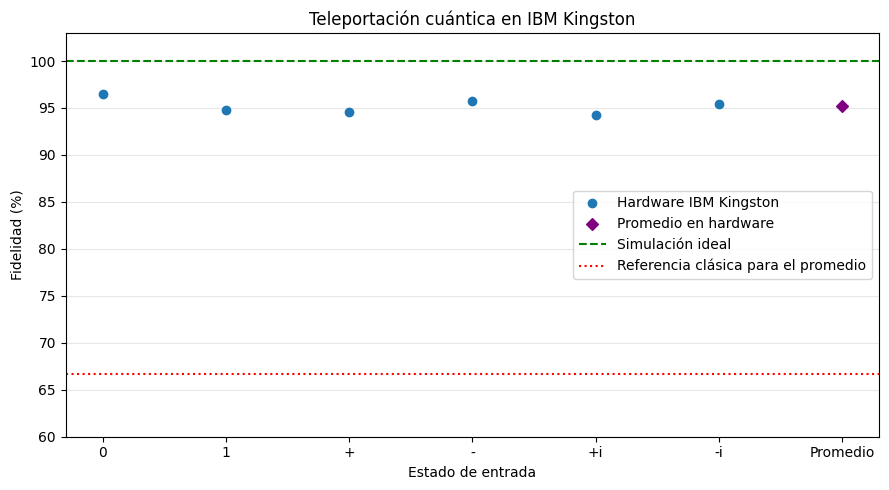

In [ ]:
import matplotlib.pyplot as plt

nombres = [fila["estado"] for fila in resultados_hardware]
fidelidades = [100 * fila["fidelidad"] for fila in resultados_hardware]
posiciones = list(range(len(nombres)))

plt.figure(figsize=(9, 5))
plt.scatter(posiciones, fidelidades, label="Hardware IBM Kingston", zorder=3)

plt.scatter(
    len(nombres),
    100 * fidelidad_promedio_hardware,
    marker="D",
    color="purple",
    label="Promedio en hardware",
    zorder=4
)

plt.axhline(100, color="green", linestyle="--", label="Simulación ideal")
plt.axhline(
    100 * 2 / 3,
    color="red",
    linestyle=":",
    label="Referencia clásica para el promedio"
)

plt.xticks(posiciones + [len(nombres)], nombres + ["Promedio"])
plt.xlabel("Estado de entrada")
plt.ylabel("Fidelidad (%)")
plt.title("Teleportación cuántica en IBM Kingston")
plt.ylim(60, 103)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("teleportacion_comparacion_hardware.png", dpi=300)
plt.show()